# W4D1 Audio Basics：声音与采样实验

## 实验目标

本实验完成以下内容：

1. 使用数学公式生成正弦波；
2. 理解采样率、频率、采样点数量之间的关系；
3. 保存生成的 waveform 为 WAV 文件；
4. 读取 WAV 文件并查看：
   - sample rate
   - channel
   - bit depth
   - duration
5. 验证：

$$
duration=\frac{num\_samples}{sample\_rate}
$$


## 核心流程

声音信号：

$$
模拟信号
\rightarrow
数字采样
\rightarrow
PCM
\rightarrow
float32 waveform
\rightarrow
ASR模型
$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from pathlib import Path

## 1. 设置实验参数

定义：

- sample_rate：采样率
- frequency：正弦波频率
- duration：音频长度

其中：

采样率表示：

> 每秒采集多少个样本

频率表示：

> 声音振动频率

In [3]:
sample_rate = 16000
frequency = 440
duration = 1

num_samples = sample_rate * duration

print("sample_rate:", sample_rate)
print("frequency:", frequency)
print("duration:", duration)
print("num_samples:", num_samples)

sample_rate: 16000
frequency: 440
duration: 1
num_samples: 16000


## 2. 生成时间序列

计算机不能直接表示连续时间：

$$
t
$$

因此使用采样点索引：

$$
n=0,1,2,...
$$


通过采样率转换：

$$
t=\frac{n}{f_s}
$$


其中：

- n：采样点编号
- fs：采样率

In [4]:
n = np.arange(num_samples)

t = n / sample_rate

print("time shape:", t.shape)
print("first 5 timestamps:", t[:5])

time shape: (16000,)
first 5 timestamps: [0.000e+00 6.250e-05 1.250e-04 1.875e-04 2.500e-04]


## 3. 生成正弦波 waveform


正弦波公式：

$$
x[n]=A\sin(2\pi f\frac{n}{f_s})
$$


其中：

- A：振幅
- f：频率
- fs：采样率


这里设置：

$$
A=1
$$


生成后的 waveform：

范围：

$$
[-1,1]
$$

In [5]:
amplitude = 1.0

waveform = amplitude * np.sin(
    2 * np.pi * frequency * t
)

print("waveform shape:", waveform.shape)
print("max:", waveform.max())
print("min:", waveform.min())

waveform shape: (16000,)
max: 1.0
min: -1.0


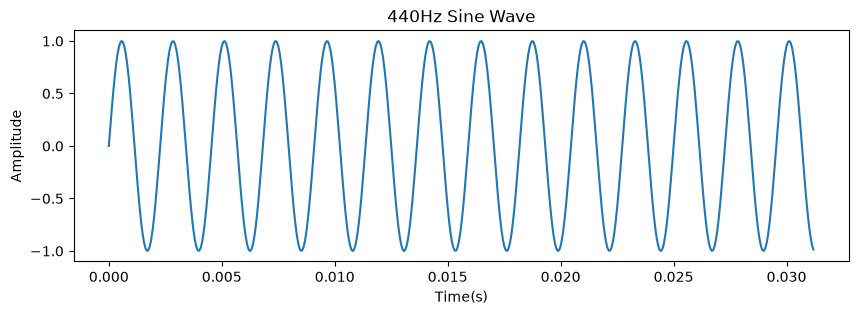

In [6]:
plt.figure(figsize=(10,3))

plt.plot(
    t[:500],
    waveform[:500]
)

plt.xlabel("Time(s)")
plt.ylabel("Amplitude")
plt.title("440Hz Sine Wave")

plt.show()

## 4. 保存 WAV 文件


模型内部通常使用：

float32 waveform


范围：

$$
[-1,1]
$$


但是 WAV 文件通常保存：

PCM int16。


转换：

$$
x_{int16}
=
x_{float32}
\times32767
$$

In [12]:
output_dir = Path("../data")

output_dir.mkdir(
    exist_ok=True
)

wav_path = output_dir / "sine_440hz.wav"

sf.write(
    wav_path,
    waveform.astype(np.float32),
    sample_rate
)

print("saved:", wav_path)

saved: ..\data\sine_440hz.wav


## 5. 读取 WAV 文件


读取后需要关注：

- waveform
- sample_rate


其中：

waveform表示：

音频采样点。


sample_rate表示：

每秒采样数量。

In [9]:
loaded_waveform, loaded_sr = sf.read(
    wav_path
)

print("sample_rate:", loaded_sr)
print("waveform shape:", loaded_waveform.shape)
print("dtype:", loaded_waveform.dtype)

sample_rate: 16000
waveform shape: (16000,)
dtype: float64


## 6. 音频信息验证


计算：

$$
duration=
\frac{num\_samples}{sample\_rate}
$$


验证读取后的音频长度是否正确。

In [10]:
num_samples_loaded = len(loaded_waveform)

duration_loaded = num_samples_loaded / loaded_sr

print("num_samples:", num_samples_loaded)
print("duration:", duration_loaded)

num_samples: 16000
duration: 1.0


# 实验总结


## 本次实验完成：

✅ 使用公式生成440Hz正弦波

✅ 理解采样率和频率区别

✅ 保存WAV文件

✅ 读取WAV文件

✅ 验证：

$$
duration=
\frac{samples}{sample\_rate}
$$


## 核心结论


声音本身是连续模拟信号，计算机通过采样转换为离散数字信号。

WAV文件通常保存PCM格式数据，而深度学习模型通常使用归一化后的float32 waveform。

ASR模型通常进一步将waveform转换为声学特征，例如：

$$
Waveform
\rightarrow
Log\text{-}Mel
\rightarrow
Encoder
$$